In [3]:
import pandas as pd

customers = pd.DataFrame({
    "client_id": [101, 102, 103, 104],
    "page_views_30d": [12, 5, 20, 0],
    "cart_adds_30d": [3, 0, 5, 0],
    "target_30d": [1, 0, 1, 0]
})

customers

,client_id,page_views_30d,cart_adds_30d,target_30d
0,101,12,3,1
1,102,5,0,0
2,103,20,5,1
3,104,0,0,0


In [4]:
customers.shape

(4, 4)

In [5]:
customers.head(2)

,client_id,page_views_30d,cart_adds_30d,target_30d
0,101,12,3,1
1,102,5,0,0


In [6]:
import importlib.util

if importlib.util.find_spec("clickhouse_connect"):
    print("ClickHouse Python client is installed.")
else:
    print("ClickHouse Python client is not installed.")

ClickHouse Python client is installed.


In [7]:
import clickhouse_connect
from getpass import getpass

client = clickhouse_connect.get_client(
    host="localhost",
    port=18123,
    username="ecommerce_app",
    password=getpass("ClickHouse password: ")
)

print("Connected to ClickHouse!")

ClickHouse password:  ········


Connected to ClickHouse!


In [8]:
df = client.query_df("""
    SELECT *
    FROM synerise_analytics.ml_customer_features
    LIMIT 10
""")

df

,client_id,first_purchase_ts,first_purchase_month,target_30d,page_views_30d,unique_pages_30d,cart_adds_30d,cart_removals_30d,searches_30d,has_cart_activity_30d,has_behavioral_activity_30d
0,33,2022-07-26 16:22:45,2022-07-01,0,10,7,1,0,0,1,1
1,80,2022-09-30 08:19:15,2022-09-01,0,30,18,6,1,4,1,1
2,84,2022-08-22 11:41:35,2022-08-01,1,51,23,1,0,1,1,1
3,292,2022-08-25 14:20:45,2022-08-01,0,0,0,0,0,0,0,0
4,387,2022-09-18 17:24:35,2022-09-01,0,0,0,0,0,0,0,0
5,425,2022-10-31 19:58:30,2022-10-01,1,8,5,1,0,0,1,1
6,472,2022-10-12 05:46:00,2022-10-01,0,1,1,1,0,0,1,1
7,587,2022-09-21 05:22:15,2022-09-01,0,0,0,0,0,0,0,0
8,617,2022-08-22 16:09:40,2022-08-01,0,6,2,0,2,0,0,1
9,619,2022-07-31 20:13:25,2022-07-01,1,40,12,8,5,5,1,1


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   client_id                    10 non-null     int64         
 1   first_purchase_ts            10 non-null     datetime64[ns]
 2   first_purchase_month         10 non-null     datetime64[ns]
 3   target_30d                   10 non-null     uint8         
 4   page_views_30d               10 non-null     uint64        
 5   unique_pages_30d             10 non-null     uint64        
 6   cart_adds_30d                10 non-null     uint64        
 7   cart_removals_30d            10 non-null     uint64        
 8   searches_30d                 10 non-null     uint64        
 9   has_cart_activity_30d        10 non-null     uint8         
 10  has_behavioral_activity_30d  10 non-null     uint8         
dtypes: datetime64[ns](2), int64(1), uint64(5), uint8(3)
memory 

In [10]:
df = client.query_df("""
    SELECT *
    FROM synerise_analytics.ml_customer_features
    ORDER BY first_purchase_ts, client_id
""")

print("Shape:", df.shape)

Shape: (547914, 11)


In [11]:
df["target_30d"].value_counts()

target_30d
0    473133
1     74781
Name: count, dtype: int64

In [12]:
df["target_30d"].value_counts(normalize=True)

target_30d
0    0.863517
1    0.136483
Name: proportion, dtype: float64

In [13]:
feature_columns = [
    "page_views_30d",
    "unique_pages_30d",
    "cart_adds_30d",
    "cart_removals_30d",
    "searches_30d",
    "has_cart_activity_30d",
    "has_behavioral_activity_30d",
]

X = df[feature_columns]
y = df["target_30d"]

In [14]:
print("X shape:", X.shape)
X.head()

X shape: (547914, 7)


,page_views_30d,unique_pages_30d,cart_adds_30d,cart_removals_30d,searches_30d,has_cart_activity_30d,has_behavioral_activity_30d
0,55,22,2,0,0,1,1
1,15,5,1,0,0,1,1
2,58,33,10,0,0,1,1
3,14,8,1,0,1,1,1
4,8,5,0,1,0,0,1


In [15]:
print("y shape:", y.shape)
y.head()

y shape: (547914,)


0    0
1    1
2    1
3    0
4    0
Name: target_30d, dtype: uint8

In [16]:
train_mask = (
    (df["first_purchase_ts"] >= "2022-07-23")
    & (df["first_purchase_ts"] < "2022-08-16")
)

val_mask = (
    (df["first_purchase_ts"] >= "2022-09-15")
    & (df["first_purchase_ts"] < "2022-10-01")
)

test_mask = (
    (df["first_purchase_ts"] >= "2022-11-01")
    & (df["first_purchase_ts"] < "2022-11-08")
)

In [17]:
X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_val = X.loc[val_mask]
y_val = y.loc[val_mask]

X_test = X.loc[test_mask]
y_test = y.loc[test_mask]

In [18]:
for name, features, target in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test),
]:
    print(
        f"{name}: {len(features):,} customers, "
        f"{target.mean():.2%} repeat purchasers"
    )

Train: 122,467 customers, 13.36% repeat purchasers
Validation: 78,700 customers, 14.34% repeat purchasers
Test: 33,020 customers, 13.45% repeat purchasers


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

In [20]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[uint8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['page_views_30d','unique_pages_30d','cart_adds_30d',...,'searches_30d', 'has_cart_activity_30d','has_behavioral_activity_30d']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [21]:
val_probabilities = model.predict_proba(X_val)[:, 1]

print("First 10 predicted probabilities:")
print(val_probabilities[:10])

First 10 predicted probabilities:
[0.138491   0.14139383 0.13391534 0.13788044 0.1421253  0.10148105
 0.13534666 0.1346977  0.19487209 0.18095977]


In [22]:
from sklearn.metrics import average_precision_score

ap = average_precision_score(y_val, val_probabilities)
baseline_ap = y_val.mean()

print(f"Logistic Regression AP: {ap:.4f}")
print(f"Baseline AP:            {baseline_ap:.4f}")

Logistic Regression AP: 0.2087
Baseline AP:            0.1434


In [23]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_val, val_probabilities)

print(f"Logistic Regression ROC-AUC: {roc_auc:.4f}")
print("Random ranking ROC-AUC:     0.5000")

Logistic Regression ROC-AUC: 0.6054
Random ranking ROC-AUC:     0.5000


In [24]:
import pandas as pd

results = pd.DataFrame({
    "probability": val_probabilities,
    "actual": y_val.to_numpy()
})

top_10_percent = results.nlargest(
    n=int(len(results) * 0.10),
    columns="probability"
)

overall_rate = results["actual"].mean()
top_rate = top_10_percent["actual"].mean()
lift_10 = top_rate / overall_rate

print(f"Overall repeat rate: {overall_rate:.2%}")
print(f"Top 10% repeat rate: {top_rate:.2%}")
print(f"Lift@10%:            {lift_10:.2f}x")

Overall repeat rate: 14.34%
Top 10% repeat rate: 26.30%
Lift@10%:            1.83x


In [25]:
from lightgbm import LGBMClassifier

lgbm_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=4,
    random_state=42,
    verbosity=-1
)

lgbm_model.fit(X_train, y_train)

,max_depth,4
,learning_rate,0.05
,random_state,42
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


In [26]:
print("LightGBM is trained!")
print("Number of trees:", lgbm_model.n_estimators_)

LightGBM is trained!
Number of trees: 100


In [27]:
lgbm_probabilities = lgbm_model.predict_proba(X_val)[:, 1]

print("First 10 LightGBM predictions:")
print(lgbm_probabilities[:10])

First 10 LightGBM predictions:
[0.10466063 0.11390334 0.12711405 0.1688533  0.1341548  0.10270067
 0.11103361 0.15061702 0.2752712  0.2389048 ]


In [28]:
from sklearn.metrics import average_precision_score, roc_auc_score

lgbm_ap = average_precision_score(y_val, lgbm_probabilities)
lgbm_roc_auc = roc_auc_score(y_val, lgbm_probabilities)

print("Model comparison — Validation dataset")
print("-" * 45)
print(f"{'Metric':<20} {'Logistic':>10} {'LightGBM':>10}")
print(f"{'Average Precision':<20} {ap:>10.4f} {lgbm_ap:>10.4f}")
print(f"{'ROC-AUC':<20} {roc_auc:>10.4f} {lgbm_roc_auc:>10.4f}")

Model comparison — Validation dataset
---------------------------------------------
Metric                 Logistic   LightGBM
Average Precision        0.2087     0.2209
ROC-AUC                  0.6054     0.6278


In [29]:
lgbm_results = pd.DataFrame({
    "probability": lgbm_probabilities,
    "actual": y_val.to_numpy()
})

lgbm_top_10 = lgbm_results.nlargest(
    n=int(len(lgbm_results) * 0.10),
    columns="probability"
)

lgbm_top_rate = lgbm_top_10["actual"].mean()
lgbm_lift_10 = lgbm_top_rate / overall_rate

print(f"Overall repeat rate:          {overall_rate:.2%}")
print(f"LightGBM top 10% repeat rate: {lgbm_top_rate:.2%}")
print(f"LightGBM Lift@10%:            {lgbm_lift_10:.2f}x")
print(f"Logistic Regression Lift@10%: {lift_10:.2f}x")

Overall repeat rate:          14.34%
LightGBM top 10% repeat rate: 27.70%
LightGBM Lift@10%:            1.93x
Logistic Regression Lift@10%: 1.83x


In [30]:
import pandas as pd

feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": lgbm_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance", ascending=False
)

feature_importance

,feature,importance
0,page_views_30d,331
1,unique_pages_30d,327
4,searches_30d,212
2,cart_adds_30d,204
3,cart_removals_30d,161
6,has_behavioral_activity_30d,34
5,has_cart_activity_30d,0


In [31]:
from lightgbm import LGBMClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

reduced_features = [
    col for col in feature_columns
    if col != "has_cart_activity_30d"
]

reduced_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=4,
    random_state=42,
    verbosity=-1
)

reduced_model.fit(
    X_train[reduced_features],
    y_train
)

reduced_probabilities = reduced_model.predict_proba(
    X_val[reduced_features]
)[:, 1]

print(
    "Original AP:",
    round(lgbm_ap, 4)
)

print(
    "Reduced AP: ",
    round(average_precision_score(y_val, reduced_probabilities), 4)
)

print(
    "Original ROC-AUC:",
    round(lgbm_roc_auc, 4)
)

print(
    "Reduced ROC-AUC: ",
    round(roc_auc_score(y_val, reduced_probabilities), 4)
)

Original AP: 0.2209
Reduced AP:  0.2209
Original ROC-AUC: 0.6278
Reduced ROC-AUC:  0.6278


In [32]:
import numpy as np

difference = np.abs(
    lgbm_probabilities - reduced_probabilities
)

print(f"Maximum prediction difference: {difference.max():.10f}")
print(f"Mean prediction difference:    {difference.mean():.10f}")

Maximum prediction difference: 0.0000000000
Mean prediction difference:    0.0000000000


In [33]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    lgbm_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

perm_importance = pd.DataFrame({
    "feature": X_val.columns,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
}).sort_values("importance_mean", ascending=False)

perm_importance

,feature,importance_mean,importance_std
1,unique_pages_30d,0.054013,0.000746
0,page_views_30d,0.022795,0.000593
4,searches_30d,0.018373,0.000752
3,cart_removals_30d,0.010550,0.000245
2,cart_adds_30d,0.008695,0.000606
6,has_behavioral_activity_30d,0.006381,0.000120
5,has_cart_activity_30d,0.000000,0.000000


In [34]:
analysis = df.copy()

analysis["unique_pages_group"] = pd.cut(
    analysis["unique_pages_30d"],
    bins=[-1, 0, 1, 3, 10, float("inf")],
    labels=["0", "1", "2–3", "4–10", "11+"]
)

summary = (
    analysis.groupby(
        "unique_pages_group",
        observed=True
    )
    .agg(
        customers=("target_30d", "size"),
        repeat_rate=("target_30d", "mean")
    )
    .reset_index()
)

summary["repeat_rate"] = (
    summary["repeat_rate"] * 100
).round(2)

summary

,unique_pages_group,customers,repeat_rate
0,0,175587,9.66
1,1,69366,20.31
2,2–3,45168,13.12
3,4–10,177772,12.17
4,11+,80021,20.20


In [35]:
train_analysis = df.loc[train_mask].copy()

train_analysis["unique_pages_group"] = pd.cut(
    train_analysis["unique_pages_30d"],
    bins=[-1, 0, 1, 3, 10, float("inf")],
    labels=["0", "1", "2–3", "4–10", "11+"]
)

train_summary = (
    train_analysis.groupby("unique_pages_group", observed=True)
    .agg(
        customers=("target_30d", "size"),
        repeat_rate=("target_30d", "mean")
    )
    .reset_index()
)

train_summary["repeat_rate"] = (
    train_summary["repeat_rate"] * 100
).round(2)

train_summary

,unique_pages_group,customers,repeat_rate
0,0,42437,10.47
1,1,6963,16.75
2,2–3,10554,13.04
3,4–10,42018,11.94
4,11+,20495,21.25


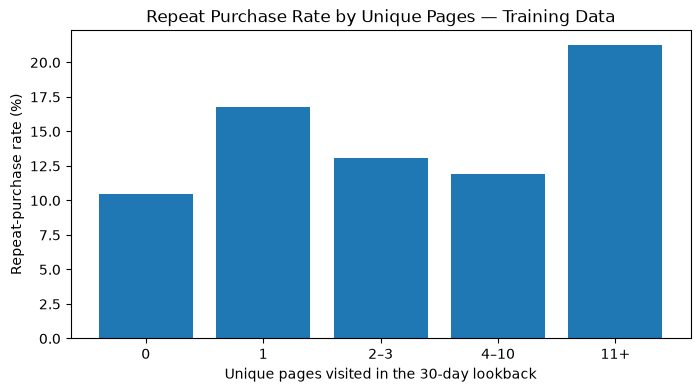

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.bar(
    train_summary["unique_pages_group"].astype(str),
    train_summary["repeat_rate"]
)

plt.xlabel("Unique pages visited in the 30-day lookback")
plt.ylabel("Repeat-purchase rate (%)")
plt.title("Repeat Purchase Rate by Unique Pages — Training Data")

plt.show()

In [37]:
import matplotlib
print(matplotlib.__version__)

3.11.2


In [39]:
from sklearn.metrics import average_precision_score

train_probabilities = lgbm_model.predict_proba(X_train)[:, 1]

train_ap = average_precision_score(y_train, train_probabilities)
val_ap = average_precision_score(y_val, lgbm_probabilities)

print(f"Training AP:   {train_ap:.2%}")
print(f"Validation AP: {val_ap:.2%}")
print(f"Difference:    {train_ap - val_ap:.2%}")

Training AP:   21.70%
Validation AP: 22.09%
Difference:    -0.39%


In [40]:
# Compare model performance against each dataset's baseline

train_baseline = y_train.mean()
val_baseline = y_val.mean()

train_ap_lift = train_ap / train_baseline
val_ap_lift = val_ap / val_baseline

print("LightGBM Performance Comparison")
print("-" * 45)

print(f"{'Metric':<20} {'Training':>10} {'Validation':>12}")
print(f"{'Baseline AP':<20} {train_baseline:>10.2%} {val_baseline:>12.2%}")
print(f"{'Model AP':<20} {train_ap:>10.2%} {val_ap:>12.2%}")
print(f"{'AP / Baseline':<20} {train_ap_lift:>10.2f}x {val_ap_lift:>11.2f}x")

LightGBM Performance Comparison
---------------------------------------------
Metric                 Training   Validation
Baseline AP              13.36%       14.34%
Model AP                 21.70%       22.09%
AP / Baseline              1.62x        1.54x


In [41]:
from sklearn.metrics import roc_auc_score

train_roc_auc = roc_auc_score(
    y_train,
    train_probabilities
)

val_roc_auc = roc_auc_score(
    y_val,
    lgbm_probabilities
)

print("LightGBM ROC-AUC Comparison")
print("-" * 40)
print(f"Training ROC-AUC:   {train_roc_auc:.4f}")
print(f"Validation ROC-AUC: {val_roc_auc:.4f}")
print(f"Difference:         {train_roc_auc - val_roc_auc:+.4f}")

LightGBM ROC-AUC Comparison
----------------------------------------
Training ROC-AUC:   0.6057
Validation ROC-AUC: 0.6278
Difference:         -0.0221


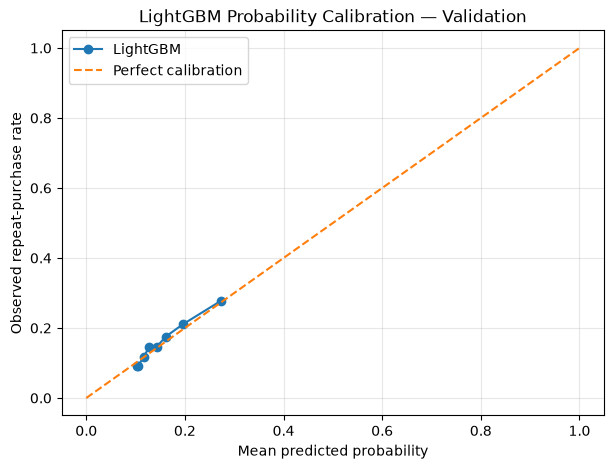

LightGBM Brier score: 0.1194


In [42]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

# Calculate observed repeat-purchase rates
prob_true, prob_pred = calibration_curve(
    y_val,
    lgbm_probabilities,
    n_bins=10,
    strategy="quantile"
)

# Calculate Brier score
brier = brier_score_loss(y_val, lgbm_probabilities)

# Plot calibration curve
plt.figure(figsize=(7, 5))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="LightGBM"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed repeat-purchase rate")
plt.title("LightGBM Probability Calibration — Validation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"LightGBM Brier score: {brier:.4f}")

In [43]:
import numpy as np
from sklearn.metrics import brier_score_loss

baseline_probabilities = np.full(
    len(y_val),
    y_train.mean()
)

baseline_brier = brier_score_loss(
    y_val,
    baseline_probabilities
)

logistic_brier = brier_score_loss(
    y_val,
    val_probabilities
)

lgbm_brier = brier_score_loss(
    y_val,
    lgbm_probabilities
)

print(f"Baseline Brier:            {baseline_brier:.4f}")
print(f"Logistic Regression Brier: {logistic_brier:.4f}")
print(f"LightGBM Brier:            {lgbm_brier:.4f}")

Baseline Brier:            0.1229
Logistic Regression Brier: 0.1211
LightGBM Brier:            0.1194


In [44]:
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
import numpy as np
import pandas as pd

# Generate predictions on untouched test data
test_probabilities = lgbm_model.predict_proba(X_test)[:, 1]

# Calculate ranking and probability metrics
test_ap = average_precision_score(y_test, test_probabilities)
test_roc_auc = roc_auc_score(y_test, test_probabilities)
test_brier = brier_score_loss(y_test, test_probabilities)

# Calculate Lift@10%
test_results = pd.DataFrame({
    "probability": test_probabilities,
    "actual": y_test.to_numpy()
})

top_10 = test_results.nlargest(
    n=int(len(test_results) * 0.10),
    columns="probability"
)

test_repeat_rate = y_test.mean()
test_top_rate = top_10["actual"].mean()
test_lift_10 = test_top_rate / test_repeat_rate

print("LightGBM — Final Test Evaluation")
print("-" * 40)
print(f"Test customers:         {len(y_test):,}")
print(f"Test repeat rate:       {test_repeat_rate:.2%}")
print(f"Average Precision:      {test_ap:.4f}")
print(f"ROC-AUC:                {test_roc_auc:.4f}")
print(f"Lift@10%:               {test_lift_10:.2f}x")
print(f"Brier score:            {test_brier:.4f}")

LightGBM — Final Test Evaluation
----------------------------------------
Test customers:         33,020
Test repeat rate:       13.45%
Average Precision:      0.2134
ROC-AUC:                0.6238
Lift@10%:               2.08x
Brier score:            0.1130


In [45]:
from sklearn.metrics import brier_score_loss
import numpy as np

test_baseline_probabilities = np.full(
    len(y_test),
    y_train.mean()
)

test_baseline_brier = brier_score_loss(
    y_test,
    test_baseline_probabilities
)

print(f"Test baseline Brier: {test_baseline_brier:.4f}")
print(f"LightGBM Brier:      {test_brier:.4f}")
print(
    f"Relative improvement: "
    f"{(1 - test_brier / test_baseline_brier):.2%}"
)

Test baseline Brier: 0.1164
LightGBM Brier:      0.1130
Relative improvement: 2.87%
